# Validação dos campos extraídos por regras

O código lê cada anúncio e tenta extrair, por regras, a **recompensa**, a **nação**, a **idade**, o **sexo** e as **marcas no corpo**.
Este caderno mede se essas regras acertam, comparando com uma amostra de anúncios **rotulados à mão** (`tests/fixtures/campos_gold.json`).
Campos `c5`. O caderno **não lê o banco**: só o arquivo de rótulos e o código local.

- **Precisão:** dos anúncios em que o código marcou o campo, quantos estavam certos. Precisão baixa = o código inventa.
- **Cobertura:** dos anúncios que de fato têm o campo, quantos o código achou. Cobertura baixa = o código deixa passar.
- **F1:** uma nota só, que combina as duas.

**Por que por período?** Se a cobertura de um campo cai com o tempo (por exemplo, o OCR dos jornais mais antigos é pior), uma "queda" desse
campo nos anúncios pode ser só **efeito de leitura**, e não uma mudança na sociedade. Medir a cobertura em cada período mostra onde isso pode acontecer.

> **Cuidado ao ler:** os rótulos foram feitos por **Claude**, não pelo grupo de pesquisa; devem ser conferidos por pessoas.
> A amostra é pequena (cerca de 20 fugas por período), então os **intervalos são largos** (intervalo de Wilson de 95%).
> Períodos com menos de 20 anúncios que de fato têm o campo aparecem com círculo aberto nos gráficos.

## Preparação: ler os rótulos e rodar o código local

In [1]:
import json
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from hdb import validacao
from hdb.estatistica import wilson

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
PERIODOS = validacao.PERIODOS
def periodo_curto(p):
    return p if p.startswith("antes") else p.split(" ")[0]
MIN_N = 20
ARQ = RAIZ / "tests" / "fixtures" / "campos_gold.json"
gold = json.loads(ARQ.read_text(encoding="utf-8")) if ARQ.exists() else []
rotulados = [g for g in gold if g.get("rotulos")]
SEM_ROTULOS = not rotulados
if SEM_ROTULOS:
    print("arquivo sem rótulos: rotule tests/fixtures/campos_gold.json")
    R = {c: {} for c in validacao.CAMPOS}
else:
    print(f"{len(rotulados)} anúncios rotulados ({sum(g['tipo'] == 'fuga' for g in rotulados)} fugas, "
          f"{sum(g['tipo'] == 'aluguel' for g in rotulados)} aluguéis)")
    R = validacao.comparar(rotulados)
if len(rotulados) != 120:
    print(f"ATENÇÃO: os comentários deste caderno foram escritos para 120 anúncios rotulados e agora são {len(rotulados)}: "
          "confira os números dos textos antes de usar.")

CAMPOS = [("recompensa", "Recompensa (fugas)"), ("nacao", "Cita nação (fugas)"), ("marcas", "Marcas no corpo (fugas)"),
          ("idade", "Idade: achou alguma (fugas)"), ("sexo", "Sexo f/m (todos)")]
fmt = lambda t: "–" if t[0] != t[0] else f"{100 * t[0]:.0f}% [{100 * t[1]:.0f}–{100 * t[2]:.0f}]"

120 anúncios rotulados (80 fugas, 40 aluguéis)


## 1. Precisão e cobertura de cada campo
`VP` = o código marcou e estava certo; `FP` = marcou e não devia; `FN` = deixou passar. Entre colchetes, o intervalo de 95%.
Em **idade** a cobertura é "o anúncio traz idade e o código achou alguma"; em **sexo**, "o anúncio diz f ou m e o código disse f ou m"
(um `FP` ali é o código dizer f/m onde o rótulo é "ambos" ou "não diz"). As linhas de **acerto** abaixo olham só os casos em que
rótulo e código acharam algo: a idade tem de cair a ±1 ano da rotulada (ou do intervalo rotulado), e o sexo tem de ser o mesmo.

In [2]:
if SEM_ROTULOS:
    display(Markdown("_Arquivo sem rótulos: rotule `tests/fixtures/campos_gold.json`._"))
else:
    linhas = []
    for campo, nome in CAMPOS:
        c = R[campo].get(validacao.TOTAL)
        if c is None:
            continue
        m = validacao.metricas(c)
        linhas.append({"Campo": nome, "n": m["n"], "VP": c["vp"], "FP": c["fp"], "FN": c["fn"],
                       "Precisão [IC 95%]": fmt(m["precisao"]), "Cobertura [IC 95%]": fmt(m["cobertura"]), "F1 [IC 95%]": fmt(m["f1"])})
    display(pd.DataFrame(linhas).set_index("Campo"))
    acerto = []
    for campo, nome in (("idade_acerto", "Idade a ±1 ano, entre os que ambos acharam"), ("sexo_acerto", "Sexo certo, entre os que ambos acharam")):
        c = R[campo].get(validacao.TOTAL)
        if c:
            acerto.append({"Medida": nome, "n": c["vp"] + c["fp"], "Acertos": c["vp"],
                           "Taxa de acerto [IC 95%]": fmt(wilson(c["vp"], c["vp"] + c["fp"]))})
    display(pd.DataFrame(acerto).set_index("Medida"))

,n,VP,FP,FN,Precisão [IC 95%],Cobertura [IC 95%],F1 [IC 95%]
Campo,,,,,,,
Recompensa (fugas),80,31,0,23,100% [89–100],57% [44–70],73% [63–81]
Cita nação (fugas),80,15,2,8,88% [66–97],65% [45–81],75% [60–86]
Marcas no corpo (fugas),80,24,0,8,100% [86–100],75% [58–87],86% [74–93]
Idade: achou alguma (fugas),80,20,1,12,95% [77–99],62% [45–77],75% [62–85]
Sexo f/m (todos),120,96,9,10,91% [85–95],91% [83–95],91% [86–94]


,n,Acertos,Taxa de acerto [IC 95%]
Medida,,,
"Idade a ±1 ano, entre os que ambos acharam",20,20,100% [84–100]
"Sexo certo, entre os que ambos acharam",96,95,99% [94–100]


**O que mostra (120 anúncios rotulados por Claude: 80 fugas e 40 aluguéis):**

- **Recompensa:** quando o código marca, acerta (precisão 100%, intervalo 89 a 100), mas **só acha 57% das recompensas que existem** (intervalo 44 a 70). Os erros são sobretudo de **grafia e de OCR**: "gralificado", "recompençado" (com ç), "recom- pensados" partido, "alviçaras" lido com letra trocada.
- **Marcas no corpo:** precisão 100% e cobertura de 75% (58 a 87).
- **Idade:** o código acha 62% das idades que existem (45 a 77), e **quando acha, acerta a idade dentro de ±1 ano em 20 de 20 casos**. Perde as idades escritas "20 e tantos annes", "annds", "unos" (OCR).
- **Nação citada:** precisão 88% (66 a 97) e cobertura de 65% (45 a 81). Perde nações que **não estão na lista do código** (Ganguela, Bambuila, Songo, Ambaca, Cassange, Mucena, Calango) ou escritas com erro ("Cabiudu"); e marca "Mina" por engano em "camisa de algodão **de Minas**" (2 casos).
- **Sexo (feminino ou masculino):** precisão e cobertura de 91%; entre os casos em que o código e o rótulo acharam algo, o sexo está certo em 95 de 96 (99%). Os erros são anúncios colados ("ambos") e palavras coladas ("humescravo").

## 2. Cobertura por período
Para cada campo, a cobertura (`VP / (VP + FN)`) em cada período, com intervalo de Wilson de 95%. **Círculo aberto** = menos de 20
anúncios que de fato têm o campo naquele período: o número é frágil.

O **teste de queda** compara a cobertura do primeiro período com pelo menos 20 positivos rotulados e a do último
(teste exato de Fisher). Sinalizamos quando a cobertura cai **mais de 15 pontos** e **p < 0,05**; sem isso, não dá para dizer que a leitura piorou.

,antes de 1831,1831–1850,1850–1871,1871–1888
Campo,,,,
Recompensa (fugas),73% [48–89] (n+=15 ⚠),67% [42–85] (n+=15 ⚠),43% [21–67] (n+=14 ⚠),40% [17–69] (n+=10 ⚠)
Cita nação (fugas),55% [28–79] (n+=11 ⚠),80% [49–94] (n+=10 ⚠),50% [9–91] (n+=2 ⚠),– (n+=0 ⚠)
Marcas no corpo (fugas),86% [60–96] (n+=14 ⚠),75% [41–93] (n+=8 ⚠),60% [23–88] (n+=5 ⚠),60% [23–88] (n+=5 ⚠)
Idade: achou alguma (fugas),17% [3–56] (n+=6 ⚠),62% [31–86] (n+=8 ⚠),86% [49–97] (n+=7 ⚠),73% [43–90] (n+=11 ⚠)
Sexo f/m (todos),88% [71–96] (n+=26),96% [82–99] (n+=27),96% [82–99] (n+=27),81% [62–91] (n+=26)


n+ = anúncios que de fato têm o campo; ⚠ = menos de 20.


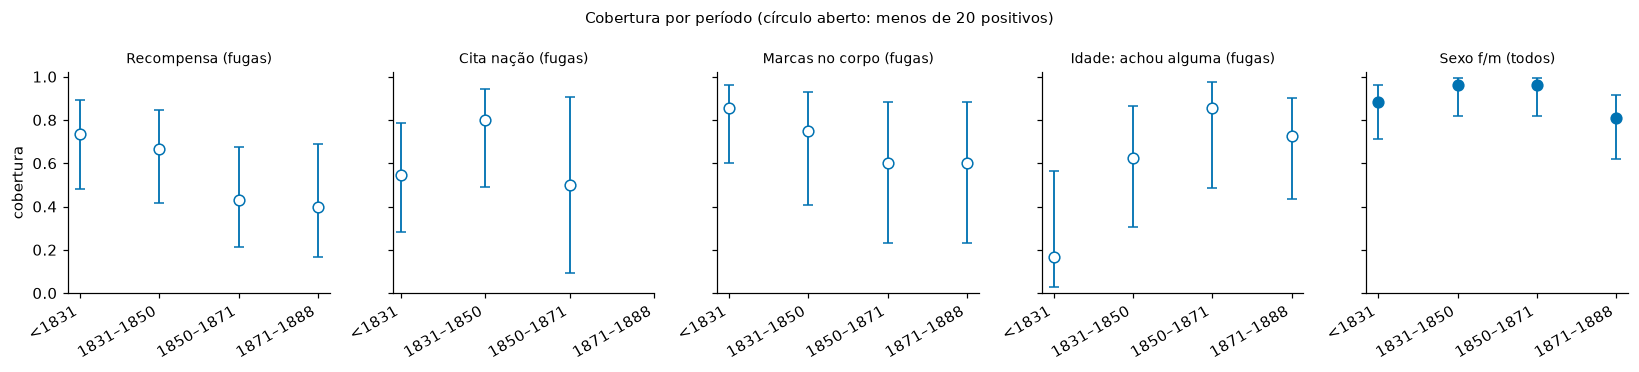

/tmp/ipykernel_1701290/1523966828.py:47: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(pd.DataFrame(linhas).set_index("Campo").fillna(""))


,Resultado,Cobertura do 1º,Cobertura do último,Diferença (pontos),p (Fisher)
Campo,,,,,
Recompensa (fugas),sem n (menos de 2 períodos com 20 positivos),,,,
Cita nação (fugas),sem n (menos de 2 períodos com 20 positivos),,,,
Marcas no corpo (fugas),sem n (menos de 2 períodos com 20 positivos),,,,
Idade: achou alguma (fugas),sem n (menos de 2 períodos com 20 positivos),,,,
Sexo f/m (todos),sem queda sinalizada,88%,81%,7.7,0.703


In [3]:
if SEM_ROTULOS:
    display(Markdown("_Arquivo sem rótulos: rotule `tests/fixtures/campos_gold.json`._"))
else:
    linhas = []
    for campo, nome in CAMPOS:
        lin = {"Campo": nome}
        for p in PERIODOS:
            c = R[campo].get(p)
            if c is None:
                lin[p] = "–"
                continue
            pos = c["vp"] + c["fn"]
            lin[p] = f"{fmt(wilson(c['vp'], pos))} (n+={pos}{' ⚠' if pos < MIN_N else ''})"
        linhas.append(lin)
    display(pd.DataFrame(linhas).set_index("Campo"))
    print("n+ = anúncios que de fato têm o campo; ⚠ = menos de 20.")

    fig, eixos = plt.subplots(1, len(CAMPOS), figsize=(3.0 * len(CAMPOS), 3.4), sharey=True)
    for ax, (campo, nome) in zip(eixos, CAMPOS):
        for i, p in enumerate(PERIODOS):
            c = R[campo].get(p)
            pos = (c["vp"] + c["fn"]) if c else 0
            if pos == 0:
                continue
            v, lo, hi = wilson(c["vp"], pos)
            ax.errorbar(i, v, yerr=[[v - lo], [hi - v]], color="#0072B2", capsize=3, lw=1.2)
            ax.plot(i, v, "o", color="#0072B2", mfc="white" if pos < MIN_N else "#0072B2", ms=7, zorder=3)
        ax.set_xticks(range(len(PERIODOS)))
        ax.set_xticklabels([periodo_curto(p).replace("antes de ", "<") for p in PERIODOS], rotation=30, ha="right")
        ax.set_title(nome, fontsize=9)
        ax.set_ylim(0, 1.02)
    eixos[0].set_ylabel("cobertura")
    fig.suptitle("Cobertura por período (círculo aberto: menos de 20 positivos)", fontsize=10)
    fig.tight_layout()
    plt.show()

    linhas = []
    for campo, nome in CAMPOS:
        q = validacao.queda_de_cobertura({p: R[campo][p] for p in PERIODOS if p in R[campo]}, min_n=MIN_N)
        if q == "sem n":
            linhas.append({"Campo": nome, "Resultado": "sem n (menos de 2 períodos com 20 positivos)"})
        else:
            ca, cu, queda, p, sinal = q
            linhas.append({"Campo": nome, "Cobertura do 1º": f"{100 * ca:.0f}%", "Cobertura do último": f"{100 * cu:.0f}%",
                           "Diferença (pontos)": round(queda, 1), "p (Fisher)": round(p, 3),
                           "Resultado": "QUEDA SINALIZADA" if sinal else "sem queda sinalizada"})
    display(pd.DataFrame(linhas).set_index("Campo").fillna(""))

**O que mostra (cobertura por período, só entre as fugas que de fato têm o campo):** a **cobertura da recompensa cai** de 73% (antes de 1831, 15 anúncios) para 67%, 43% e **40% em 1871–1888** (10 anúncios); a das marcas, de 86% para 60%. A **cobertura da idade vai no sentido contrário**: 17% antes de 1831 (6 anúncios) e 73% em 1871–1888, porque nos anúncios mais antigos as idades vêm escritas de formas que o OCR estraga. O teste de queda de cobertura diz **"sem n"** para quase todos os campos, porque poucos períodos têm 20 anúncios com o campo; as diferenças vêm com intervalos largos (por exemplo, recompensa 11/15 contra 4/10, p = 0,12 pelo teste exato de Fisher).

## 2b. A verdade por período contra o que o código vê
Nas **fugas rotuladas** (20 por período), quantas de fato têm o campo (**verdade**) e quantas o código achou (**código**), e o teste exato de Fisher entre o
primeiro e o último período. Se o código vê uma queda **maior** que a real, parte da queda é **efeito de leitura** (o OCR ou a grafia escondem o campo).
Com 20 anúncios por período o teste tem pouco poder: **p alto não prova que não houve mudança**, só que esta amostra não a mostra.

In [4]:
if SEM_ROTULOS:
    display(Markdown("_Arquivo sem rótulos._"))
else:
    from scipy.stats import fisher_exact
    fugas = [g for g in rotulados if g["tipo"] == "fuga"]
    ext = {g["id"]: validacao.extrair_para_comparar(g["texto"]) for g in fugas}
    def tem(g, campo, fonte):
        if fonte == "verdade":
            r = g["rotulos"]
            return bool(r["nacoes"]) if campo == "nacao" else (r["idade"] is not None if campo == "idade" else bool(r[campo]))
        e = ext[g["id"]]
        return bool(e["nacoes"]) if campo == "nacao" else (e["idade"] is not None if campo == "idade" else bool(e[campo]))
    linhas = []
    for campo, nome in (("recompensa", "Recompensa"), ("nacao", "Nação citada"), ("marcas", "Marcas no corpo"), ("idade", "Idade citada")):
        for fonte in ("verdade", "código"):
            ks = []
            for per in PERIODOS:
                gp = [g for g in fugas if periodo_curto(g["periodo"]) == per]
                ks.append((sum(tem(g, campo, fonte) for g in gp), len(gp)))
            (k1, n1), (k2, n2) = ks[0], ks[-1]
            p = fisher_exact([[k1, n1 - k1], [k2, n2 - k2]])[1]
            linhas.append({"Campo": nome, "Fonte": fonte,
                           **{per: f"{k}/{n} ({100 * k / n:.0f}%)" for per, (k, n) in zip(PERIODOS, ks)},
                           "p (1º × último)": "<0,001" if p < 0.001 else f"{p:.3f}".replace(".", ",")})
    display(pd.DataFrame(linhas).set_index(["Campo", "Fonte"]))

antes de 1831    1831–1850    1850–1871    1871–1888 p (1º × último)
Campo           Fonte                                                                       
Recompensa      verdade   15/20 (75%)  15/20 (75%)  14/20 (70%)  10/20 (50%)           0,191
                código    11/20 (55%)  10/20 (50%)   6/20 (30%)   4/20 (20%)           0,048
Nação citada    verdade   11/20 (55%)  10/20 (50%)   2/20 (10%)    0/20 (0%)          <0,001
                código     6/20 (30%)   9/20 (45%)    1/20 (5%)    1/20 (5%)           0,091
Marcas no corpo verdade   14/20 (70%)   8/20 (40%)   5/20 (25%)   5/20 (25%)           0,010
                código    12/20 (60%)   6/20 (30%)   3/20 (15%)   3/20 (15%)           0,008
Idade citada    verdade    6/20 (30%)   8/20 (40%)   7/20 (35%)  11/20 (55%)           0,200
                código      1/20 (5%)   5/20 (25%)   6/20 (30%)   9/20 (45%)           0,008

**O que mostra (a verdade contra o que o código vê):**

- **Recompensa:** o código vê **55%, 50%, 30%, 20%** (queda significativa, p = 0,048), mas a **verdade rotulada** é **75%, 75%, 70%, 50%** (p = 0,19, não significativa). **A queda que o código mostra é muito mais íngreme que a real**, porque ele perde cada vez mais recompensas nos períodos recentes. Com 20 anúncios por período, a queda real de 75% para 50% é plausível, mas **esta amostra não a comprova**.
- **Nação citada:** a verdade é **55%, 50%, 10%, 0%** (p < 0,001): **a queda é real** e o código até a **subestima** (vê 30%, 45%, 5%, 5%).
- **Marcas no corpo:** a verdade é **70%, 40%, 25%, 25%** (p = 0,010) e o código vê 60%, 30%, 15%, 15%: **a queda é real**, só um pouco menor no código.
- **Idade citada:** a verdade é **30%, 40%, 35%, 55%** (p = 0,20) e o código vê **5%, 25%, 30%, 45%** (p = 0,008): **a "alta" da idade citada é, em grande parte, o código aprendendo a ler idades nos anúncios mais novos**.

## 3. Onde o código erra
Até 10 **falsos negativos** (o campo existe e o código não achou) e 10 **falsos positivos** (o código marcou e não devia) por campo,
com o começo do texto, o rótulo e o que o código extraiu.

In [5]:
if SEM_ROTULOS:
    display(Markdown("_Arquivo sem rótulos: rotule `tests/fixtures/campos_gold.json`._"))
else:
    for campo, nome in CAMPOS:
        c = R[campo].get(validacao.TOTAL)
        if c is None:
            continue
        fn = [e for e in c["erros"] if e["rotulo"] and not e["extraido"]]
        fp = [e for e in c["erros"] if e["extraido"] and not e["rotulo"]]
        outros = [e for e in c["erros"] if e not in fn and e not in fp]   # sexo: rótulo f/m e código disse o contrário etc.
        display(Markdown(f"### {nome}: {c['fn']} falsos negativos, {c['fp']} falsos positivos"))
        for titulo, lista in (("Falsos negativos", fn), ("Falsos positivos", fp), ("Outros erros", outros)):
            if not lista:
                continue
            tabela = pd.DataFrame([{"id": e["id"], "rótulo": e["rotulo"], "código": e["extraido"], "trecho": e["trecho"]}
                                   for e in lista[:10]]).set_index("id")
            display(Markdown(f"**{titulo}** (mostrando {min(10, len(lista))} de {len(lista)})"))
            with pd.option_context("display.max_colwidth", 200):
                display(tabela)

### Recompensa (fugas): 23 falsos negativos, 0 falsos positivos

**Falsos negativos** (mostrando 10 de 23)

,rótulo,código,trecho
id,,,
13825,True,False,"e jaqueta de ganga azul já uzada: supõe-se que auda nos suburbios do engenho novo, e Campo de 5. Christovão. Este escravo perten. ce desde hoje em diante a Igna"
13998,True,False,"44 Fugio hum pardo de nome Ancelmo O ual he de estatura ordinaria, pouca barba; he hum tanto magroja fusco da côr, estava depouitado em. poder do actual. Carcer"
37681,True,False,"“20 Desapparec.o Sabbado passado hum preto ginhador com huma “caixa da marea L.G. n. 20 ; contendo vinte musicas para relogios de mezas, .Toga-se à quem foreu a"
37734,True,False,"“29 * Pugio ha quatro mezes, pouco mais ou menos y huma escrava, de nome Saphia, de idade Jo anvos, de estatura “pouco mois da ordinaria, term o costume de dize"
29555,True,False,"FUGIO,, de bordo do brigue-escuna Constante, um pardo de nome Manoel , idade 18 annos , alto, e triguciro , cabello-meio corrido , e grande A falla grossa, o ba"
33752,True,False,"FUGIO, no dia 2 de julho de 1844, do largo de Santa Rita n. 14, um preto de nome Casimiro ; levou vestido calça e camisa de algodao de Minas, é crioulo ds Perna"
33915,True,False,"FUGIO, ao amanhecer do dia 24 do corrente, um preto de nome Filippe , de nação , baixo e fulo ; levou vestido calça o camisa de riscado azul de algodão ; consta"
34066,True,False,"Fugio, no dia 28 de maio do corrente » enno, um preto de nação Moçambique, de 30 à 40 unos, de altura regular, com barba bastante rapada . brinco na orelha, fal"
37881,True,False,"49 No dia q do corrente mez , (ugio da casa da vinxa de Diogo Gumes Barroso, hum pardo de nome Juão, idade 14 uunos , que paresse caboculo em rasão de ter o cab"


### Cita nação (fugas): 8 falsos negativos, 2 falsos positivos

**Falsos negativos** (mostrando 8 de 8)

,rótulo,código,trecho
id,,,
5910,[Ganguela],[],"310. A Luiza Maria do Nascimento fugio à 4 annos pouco mais ou menos huma escrava por nome Maria"", Nação, Gangue: la, gorda, estatura ordinaria, e com hum signa"
13784,[Bambuilo],[],"85. Eugio hum preto. Nação Banbuillo ;.eg= atura ordinaria , cara comprida : tego de hum olho,; quem o achar procure na Tua. do Rozario: N. 33. 36- No dia 26 de"
13801,[Songo],[],"fusio bum preto de Nação Songo, estatura ordinaria, tem o perna esquerda junto ao tornozello do pê mais grossa, por ser costumado a dar ezirpellas na mesma, ter"
37773,[Ambaca],[],"15 No dia 8 do corrente desapareceo on Ffurtario; | - da casa n. 19 da rua nova de $. Bento, hum moleque novo de nação Ambaque , o qual dá pelo nome de Ray-: mu"
37846,[Cassange],[],"3 Desapareceo huma negra de nome Pamilia, ainda bugal, hindo buscar agoa a Carioca, vestida com vestido de riscado de xadrez rouxo , estatura ordinaria , rosto"
29918,[Mucena],[],"Vugio da padaria do largo dó Machado, em stembro do corrente anno 4 um preto de nação Mucena , de nome Francisco , idade de 25 a 28 annos, altura ordi + fino de"
38138,[Cabinda],[],"““PUGIO no dia 13 do corrente, da rua do Aljube , hum esttavo ' por nome Just, de nação Cabiudu; * Votou huintá argola “de ferro ao pescoço + he alto e magro ,"
25207,[Calango],[],"Ande fugido desde 23 de Abril imo passado o preto Paula de nação Calango, estatara Vaixa; barriga grande e quebrádo dá verilha direita; olhos'camudos e muito pe"


... (9 outputs left out)

,rótulo,código,trecho
id,,,
20746,None,"(1, 1)","Gratifi tin acima a quem appretender o entregar ao administrador do Dr. À. Leitão da Cunha o escravo Hermenegildo, pardo, 1 aunos, labios grossos, cabello encar"


### Sexo f/m (todos): 10 falsos negativos, 9 falsos positivos

**Outros erros** (mostrando 10 de 19)

,rótulo,código,trecho
id,,,
5892,m,nao_diz,"35. Falta, ha 10 dias, humescravo, por nome Paulo, Na» ção Congo, idade 20 e tantos annes; quitandeiro, com os dentes de diante quebrados, e huma cicattiz' junt"
13928,m,nao_diz,"93 José Alves de Castilhos, tem notícia que a bordo de huma embarcação de Guerra, se acha bum cabra official de Tanueiro, justo pa- 2» ? trabalho com o titulo d"
37690,m,nao_diz,"35 Bm 01.0 do mez pp, fugia da Fazenda do Capitão .Justinianao de Oliveira Teguudes, situada em Suruy, hum pirdo escuro de nome Mandel, o qual foi escravo na Fa"
37881,ambos,m,"49 No dia q do corrente mez , (ugio da casa da vinxa de Diogo Gumes Barroso, hum pardo de nome Juão, idade 14 uunos , que paresse caboculo em rasão de ter o cab"
38138,ambos,f,"““PUGIO no dia 13 do corrente, da rua do Aljube , hum esttavo ' por nome Just, de nação Cabiudu; * Votou huintá argola “de ferro ao pescoço + he alto e magro ,"
22661,m,nao_diz,"Avda fugido desde q dia 26 de dezembro de 1830, preto Firmo, criculo , que foi escravo do Dr. Car. rão , da fazenda do Codeço, tento es signaes ses guintos : lu"
24431,nao_diz,m,"EXTMANTO DIARIO DO DIA.6 DE DEZEMBAO Na freguezia do Sacramento ferão presos 'o subdelegado, José Ribeiro da Silva, para ave Miguel Antonio Gonçalves Portella,"
11881,m,ambos,"'ugio da rua de &. Bento m. 430 escravo Jere s, nO dia 28 deDezembro proximo findo: é baixo, . côr um tanto fula e levou calça e camisa de Eme co ao eo dr mr mu"
17767,m,nao_diz,"- O SE Ã é To! 7 re - PEQRAVO FUGIDO qusinheiro, magro e"


## 4. O que isso diz e o que não diz

**O que a validação autoriza:**

1. **A queda da nação citada nas fugas é real** (conferida à mão: 11 de 20 antes de 1831, nenhuma de 20 em 1871–1888) e **a queda das marcas no corpo também** (14 de 20 para 5 de 20).
2. **A queda da recompensa NÃO está comprovada.** O código a exagera: ele perde mais recompensas nos períodos recentes. Na amostra rotulada, a recompensa vai de 75% para 50% sem significância. **Não apresentar o número do código (56% para 23%) como medida da queda.**
3. **Idade:** o código acha poucas idades antes de 1831 (17%), então a idade mediana do primeiro período (e a "alta" dela) **não é confiável**.
4. **Sexo** é o campo mais confiável (99% de acerto quando o código acha); ressalva só para anúncios colados.

**Limites:** a amostra tem 20 fugas por período (e poucos positivos por campo nos períodos recentes), então os testes têm pouco poder; **os rótulos são de Claude, não do grupo**; o arquivo `tests/fixtures/campos_gold.json` permite ao grupo conferir.

**O que fazer depois (tarefa seguinte):** corrigir as regras que mais perdem campos: aceitar "gralificado", "recompençado" e palavras partidas pelo OCR na recompensa; ampliar a lista de nações (e tirar "de Minas"); e ler idades escritas "20 e tantos" com OCR sujo.